In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [2]:
import h5py as h5

f = h5.File('sample_2e7_design_precessing_higherordermodes_3detectors.h5', 'r')
fkeys = list(f.keys())
for i in range(len(fkeys)):
    print(i, fkeys[i])

0 chi1x
1 chi1y
2 chi1z
3 chi2x
4 chi2y
5 chi2z
6 dec
7 det
8 iota
9 mtot
10 psi
11 q
12 ra
13 snr
14 z


In [3]:
for k in f.keys(): lensample = f[k].size #print(lensample)
nkeys = np.shape(fkeys)[0]
nfeat = nkeys - 2

ffeat = []
X = np.zeros((nfeat, lensample))
j = 0
for i in range(nkeys):
    if i == 7: continue
    if i == 13: continue
    #print(j)
    ffeat.append(fkeys[i])
    X[j] = f[fkeys[i]]
    print(j, fkeys[i])
    j += 1

X = X.T

y = f['det']
y = np.array(y)

0 chi1x
1 chi1y
2 chi1z
3 chi2x
4 chi2y
5 chi2z
6 dec
7 iota
8 mtot
9 psi
10 q
11 ra
12 z


In [4]:
f.close()

In [5]:
ss_size = int(5e4)
X = X[:ss_size]
y = y[:ss_size]
print(X.shape, y.shape)

(50000, 13) (50000,)


Performing test-train-validation splitting with the following fractions: 50%, 25%, 25%, respectively:

In [6]:
from sklearn.model_selection import train_test_split as tts

X_train, X2, y_train, y2 = tts(X, y, train_size=0.5)
X_test, X_valid, y_true, y_valid = tts(X2, y2, train_size=0.5)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_true.shape)
print(X_valid.shape, y_valid.shape)

(25000, 13) (25000,)
(12500, 13) (12500,)
(12500, 13) (12500,)


Let's now normalize the data:

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
print('means \n', scaler.mean_)
print('stds \n', np.sqrt(scaler.var_))

X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)

means 
 [-7.92867042e-04 -2.28300307e-03 -8.72875177e-04  4.60189144e-03
 -8.57995971e-04 -2.15985098e-03 -5.75965962e-03  1.56997751e+00
  5.04281282e+02  1.57505464e+00  5.49814218e-01 -3.70920188e-03
  2.00108302e+00]
stds 
 [3.31952196e-01 3.34095237e-01 3.35099322e-01 3.36015421e-01
 3.34058523e-01 3.33381599e-01 6.82147998e-01 6.83604615e-01
 2.88187548e+02 9.02929373e-01 2.59149814e-01 1.81685579e+00
 1.15347353e+00]


In [44]:
from tensorflow.keras import regularizers

model = keras.models.Sequential([
    keras.layers.InputLayer(input_shape=[X_train.shape[1]]), 
    keras.layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2()),
    keras.layers.Dropout(0.4),
    keras.layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2()),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l2()),
    keras.layers.Dense(1, activation='sigmoid')
])
print(model.summary())

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_16 (Dense)            (None, 64)                896       
                                                                 
 dropout_8 (Dropout)         (None, 64)                0         
                                                                 
 dense_17 (Dense)            (None, 32)                2080      
                                                                 
 dropout_9 (Dropout)         (None, 32)                0         
                                                                 
 dense_18 (Dense)            (None, 16)                528       
                                                                 
 dense_19 (Dense)            (None, 1)                 17        
                                                                 
Total params: 3521 (13.75 KB)
Trainable params: 3521 (

In [45]:
from tensorflow.keras.optimizers.legacy import Nadam

batch_size = 100
n_epochs = 100
learning_rate = 1e-4
model.compile(loss="binary_crossentropy", optimizer=Nadam(learning_rate=learning_rate), metrics=["accuracy"])
clf = model.fit(X_train, y_train, batch_size=batch_size, epochs=n_epochs, validation_data=(X_valid, y_valid))

Epoch 1/100
250/250 [==============================] - 9s 31ms/step - loss: 1.5949 - accuracy: 0.5932 - val_loss: 1.2746 - val_accuracy: 0.7704
Epoch 2/100
250/250 [==============================] - 8s 31ms/step - loss: 1.2609 - accuracy: 0.7235 - val_loss: 1.0834 - val_accuracy: 0.8799
Epoch 3/100
250/250 [==============================] - 8s 30ms/step - loss: 1.0766 - accuracy: 0.8017 - val_loss: 0.9463 - val_accuracy: 0.8965
Epoch 4/100
250/250 [==============================] - 8s 30ms/step - loss: 0.9349 - accuracy: 0.8437 - val_loss: 0.8341 - val_accuracy: 0.8869
Epoch 5/100
250/250 [==============================] - 8s 31ms/step - loss: 0.8236 - accuracy: 0.8621 - val_loss: 0.7394 - val_accuracy: 0.8776
Epoch 6/100
250/250 [==============================] - 8s 31ms/step - loss: 0.7263 - accuracy: 0.8711 - val_loss: 0.6576 - val_accuracy: 0.8752
Epoch 7/100
250/250 [==============================] - 8s 31ms/step - loss: 0.6444 - accuracy: 0.8770 - val_loss: 0.5858 - val_accuracy:

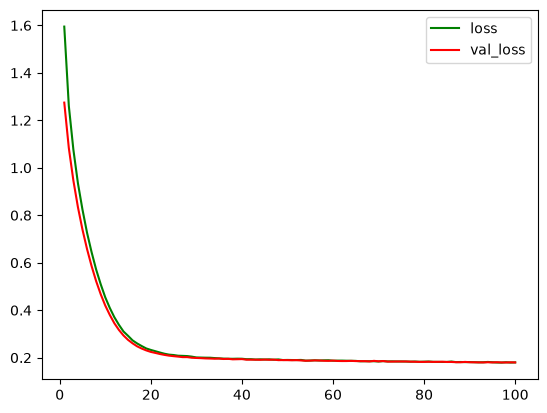

In [46]:
loss = clf.history['loss']
val_loss = clf.history['val_loss']
epochs = range(1, len(loss)+1)

plt.plot(epochs, loss, c='green', label='loss')
plt.plot(epochs, val_loss, c='red', label='val_loss')
plt.legend()
plt.show()

In [47]:
from sklearn.metrics import confusion_matrix

y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)
cm = confusion_matrix(y_true, y_pred)
print(cm)

391/391 [==============================] - 1s 1ms/step
[[10400   279]
 [  463  1358]]


In [48]:
results = model.evaluate(X_test, y_true, verbose=0)
print(f"Loss: {results[0]:.4f} | Accuracy: {results[1]:.4f}")

Loss: 0.1799 | Accuracy: 0.9406


# Trash

In [ ]:
from sklearn.utils import class_weight

weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train)

classes_weights = dict(enumerate(weights))
classes_weights

{0: 0.5831855929831109, 1: 3.5053280987100393}